# Support Vector Machine — Does This Patient Have Heart Disease?

A **Support Vector Machine (SVM)** separates two classes by drawing the dividing line that leaves the **widest empty street** between them. The points on the edge of that street — the **support vectors** — are the only ones that shape the line.

Here we'll use the classic **Cleveland Heart Disease** dataset: predict whether a patient has heart disease from 13 clinical measurements (age, blood pressure, cholesterol, ECG results, and so on).

> If you also worked through the **credit-default** notebook, watch the difference: there the classes were badly imbalanced (78/22) and the model missed most defaulters. Here the classes are **nearly balanced (~54/46)** — and you'll see how much healthier the recall looks as a result.

In [1]:
import pandas as pd

# The raw file uses '?' for missing values — tell pandas to read those as NaN
df = pd.read_csv('heart_disease.csv', na_values='?')
print('rows, columns:', df.shape)
df.head()

rows, columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### What the columns mean

All 13 features are clinical measurements. Several are **codes, not quantities**:

- `age` — age in years
- `sex` — **1 = male, 0 = female**
- `cp` — chest pain type: **1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic**
- `trestbps` — resting blood pressure (mm Hg)
- `chol` — serum cholesterol (mg/dl)
- `fbs` — fasting blood sugar > 120 mg/dl (**1 = true, 0 = false**)
- `restecg` — resting ECG: **0 = normal, 1 = ST-T abnormality, 2 = left-ventricular hypertrophy**
- `thalach` — maximum heart rate achieved
- `exang` — exercise-induced angina (**1 = yes, 0 = no**)
- `oldpeak` — ST depression induced by exercise
- `slope` — slope of the peak exercise ST segment: **1 = upsloping, 2 = flat, 3 = downsloping**
- `ca` — number of major vessels (0–3) colored by fluoroscopy
- `thal` — **3 = normal, 6 = fixed defect, 7 = reversible defect**
- `num` — **the raw diagnosis: 0 = no disease, 1–4 = increasing severity of disease**

## Cleaning & preprocessing

### Step 1 — Handle missing values

A couple of columns (`ca` and `thal`) have a few missing entries. Let's see how many:

In [2]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Only **6 rows** out of 303 have a blank. With so few, the simplest honest choice is to **drop them** — we lose almost nothing and avoid guessing values.

In [3]:
df = df.dropna()
print('rows remaining:', df.shape[0])

rows remaining: 297


### Framing the target: disease vs. no disease

The raw `num` column runs 0–4 (severity levels). We only care about a **yes/no** question — *does the patient have heart disease at all?* So we collapse it into a single binary target: `0` stays `0`, and anything `1–4` becomes `1`.

In [4]:
df['target'] = (df['num'] > 0).astype(int)   # 1 = has disease, 0 = healthy
df['target'].value_counts(normalize=True).round(3)

target
0    0.539
1    0.461
Name: proportion, dtype: float64

About **54% healthy, 46% disease** — a well-balanced target. That balance is good news: the model won't be tempted to just guess the majority class, so both precision and recall have a fair chance.

### Step 2 — Scale the features

SVM measures **distances**, and our columns are on very different scales (`chol` in the hundreds, `oldpeak` around 0–6). **`StandardScaler`** puts every feature on the same footing (mean 0, standard deviation 1) so none dominates just because its numbers are bigger.

In [5]:
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['num', 'target'])   # the 13 features
y = df['target']                         # what we want to predict

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('features:', X.shape[1])

features: 13


## Train / test split

This dataset is small (~297 patients), so SVM trains in a blink — no need to subsample. We hold out 20% to test on, and pass `stratify=y` so both sets keep the same healthy/disease balance.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

print('training patients:', X_train.shape[0])
print('testing patients:', X_test.shape[0])

training patients: 237
testing patients: 60


## Train the SVM

We'll use `SVC` with the default `rbf` kernel, which allows a curved boundary between the two groups.

In [7]:
from sklearn.svm import SVC

model = SVC(kernel='rbf')
model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Evaluate

The headline accuracy first:

In [8]:
model.score(X_test, y_test)

0.85

### Classification report

Because the classes are balanced, this accuracy is trustworthy — but the per-class breakdown still tells us more. In a medical setting, **recall on the `disease` class** is what matters most: of the patients who really are sick, how many did we catch?

In [9]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred,
                            target_names=['no disease (0)', 'disease (1)']))

                precision    recall  f1-score   support

no disease (0)       0.83      0.91      0.87        32
   disease (1)       0.88      0.79      0.83        28

      accuracy                           0.85        60
     macro avg       0.85      0.85      0.85        60
  weighted avg       0.85      0.85      0.85        60



Notice how **both classes score well** — recall on the `disease` class is around **0.8**, far healthier than the ~0.3 we saw in the imbalanced credit-default notebook. Same algorithm, same two preprocessing steps — the difference is almost entirely the **class balance** of the data.

### Confusion matrix

Rows are the truth, columns are the model's guess. The bottom-left cell — sick patients the model called healthy (**false negatives**) — is the dangerous kind of error in medicine.

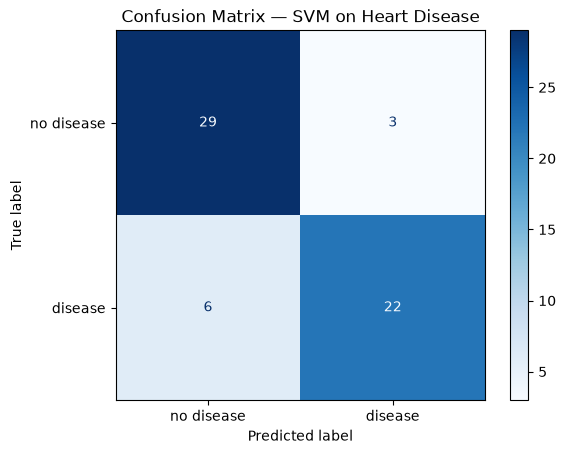

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['no disease', 'disease'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — SVM on Heart Disease')
plt.show()

## Tuning the SVM — comparing `C` and `gamma`

The `rbf` kernel has two dials that control the shape of the boundary:

- **`C` (regularization)** — how harshly the model is punished for misclassifying training points. **Low `C`** → a smoother, simpler boundary (risk: *underfitting*). **High `C`** → a wigglier boundary that tries hard to fit every training point (risk: *overfitting*).
- **`gamma`** — how far a single point's influence reaches. **Low `gamma`** → far reach, smoother boundary. **High `gamma`** → each point only sways its close neighbours, giving a tighter, more complex boundary (risk: *overfitting*).

Let's train the same SVM with a few `(C, gamma)` combinations and compare their classification reports.

In [11]:
# Train the same SVM with different C and gamma values and compare
configs = [
    (1.0, 'scale'),   # our original default
    (0.1, 'scale'),   # weaker C -> simpler, smoother boundary
    (10,  'scale'),   # stronger C -> fits training data harder
    (1.0, 0.01),      # small gamma -> very smooth boundary
    (10,  0.1),       # high C + high gamma -> most complex boundary
]

for C, gamma in configs:
    m = SVC(kernel='rbf', C=C, gamma=gamma)
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(f'===== C={C}, gamma={gamma}  |  accuracy={m.score(X_test, y_test):.3f} =====')
    print(classification_report(y_test, pred,
                                target_names=['no disease', 'disease']))

===== C=1.0, gamma=scale  |  accuracy=0.850 =====
              precision    recall  f1-score   support

  no disease       0.83      0.91      0.87        32
     disease       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60

===== C=0.1, gamma=scale  |  accuracy=0.867 =====
              precision    recall  f1-score   support

  no disease       0.83      0.94      0.88        32
     disease       0.92      0.79      0.85        28

    accuracy                           0.87        60
   macro avg       0.88      0.86      0.86        60
weighted avg       0.87      0.87      0.87        60

===== C=10, gamma=scale  |  accuracy=0.833 =====
              precision    recall  f1-score   support

  no disease       0.82      0.88      0.85        32
     disease       0.85      0.79      0.81        28

    accuracy                     

### What to notice

The scores barely move — they all sit in the low-to-mid **80s** with solid `disease` recall. That's a healthy sign: on clean, balanced data the default settings were already close to the sweet spot, and the model isn't fragile to the exact `C`/`gamma` choice.

Contrast this with the credit-default notebook, where pushing `C` and `gamma` too high made the model **overfit** and its test accuracy actually dropped. Here the data is well-behaved enough that tuning gives only small nudges. The lesson: **tune, but don't expect miracles** — the biggest wins usually come from better data, not a lucky hyperparameter.

## What we learned

- **SVM** separates classes by the **widest street** between them, defined by its **support vectors**.
- Our two preprocessing steps were **handling missing values** (dropping 6 incomplete rows) and **scaling** the features — scaling is essential because SVM is distance-based.
- We reframed a 5-level severity score into a clean **binary** question (disease vs. no disease).
- With **balanced classes**, accuracy is meaningful and recall on the important class stays high — a stark contrast to imbalanced data, where the same model quietly ignores the rare class.
- **Tuning `C` and `gamma`** only nudged the scores here — on clean, balanced data the defaults were already near-optimal.

**Try next:**
- Switch to `kernel='linear'` and compare against the `rbf` results above.
- Use `GridSearchCV` to search `C` and `gamma` automatically instead of by hand.
- Inspect which features matter most (e.g. train a `LinearSVC` and look at its coefficients).